In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization
from tqdm import tqdm
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

In [2]:
train_dir = '/kaggle/input/plantvillage-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train'
valid_dir = '/kaggle/input/plantvillage-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid'
test_dir = '/kaggle/input/plantvillage-dataset/test'

In [3]:
filenames_train = []
label_train = []
folds = os.listdir(train_dir)
for fold in folds: 
    FoldPath = os.path.join(train_dir, fold)
    files = os.listdir(FoldPath)
    for file in tqdm(files):
        filepath = os.path.join(FoldPath,file)
        filenames_train.append(filepath)
        label_train.append(fold)

100%|██████████| 1859/1859 [00:00<00:00, 708579.71it/s]


In [4]:
filenames_valid = []
label_valid = []
folds = os.listdir(valid_dir)
for fold in folds:
    FoldPath = os.path.join(valid_dir, fold)
    files = os.listdir(FoldPath)
    for file in tqdm(files):
        filepath = os.path.join(FoldPath,file)
        filenames_valid.append(filepath)
        label_valid.append(fold)

100%|██████████| 465/465 [00:00<00:00, 633848.35it/s]


In [5]:
df_train = pd.DataFrame({
    'filename': filenames_train,
    'label': label_train
})
df_valid = pd.DataFrame({
    'filename': filenames_valid,
    'label': label_valid
})

In [6]:
print(df_train.shape)
print(df_valid.shape)

(60930, 2)
(15231, 2)


In [7]:
df_train.head(5)


,filename,label
0,/kaggle/input/plantvillage-dataset/New Plant D...,Tomato___Late_blight
1,/kaggle/input/plantvillage-dataset/New Plant D...,Tomato___Late_blight
2,/kaggle/input/plantvillage-dataset/New Plant D...,Tomato___Late_blight
3,/kaggle/input/plantvillage-dataset/New Plant D...,Tomato___Late_blight
4,/kaggle/input/plantvillage-dataset/New Plant D...,Tomato___Late_blight


In [8]:
df_train.sample(5)

,filename,label
39781,/kaggle/input/plantvillage-dataset/New Plant D...,Tomato___Tomato_mosaic_virus
50697,/kaggle/input/plantvillage-dataset/New Plant D...,Corn_(maize)___Common_rust_
23539,/kaggle/input/plantvillage-dataset/New Plant D...,Tomato___Bacterial_spot
57753,/kaggle/input/plantvillage-dataset/New Plant D...,"Pepper,_bell___Bacterial_spot"
43986,/kaggle/input/plantvillage-dataset/New Plant D...,Apple___healthy


In [9]:
color = ['#CAE0BC','#780C28','#EAFAEA','#6E8E59']

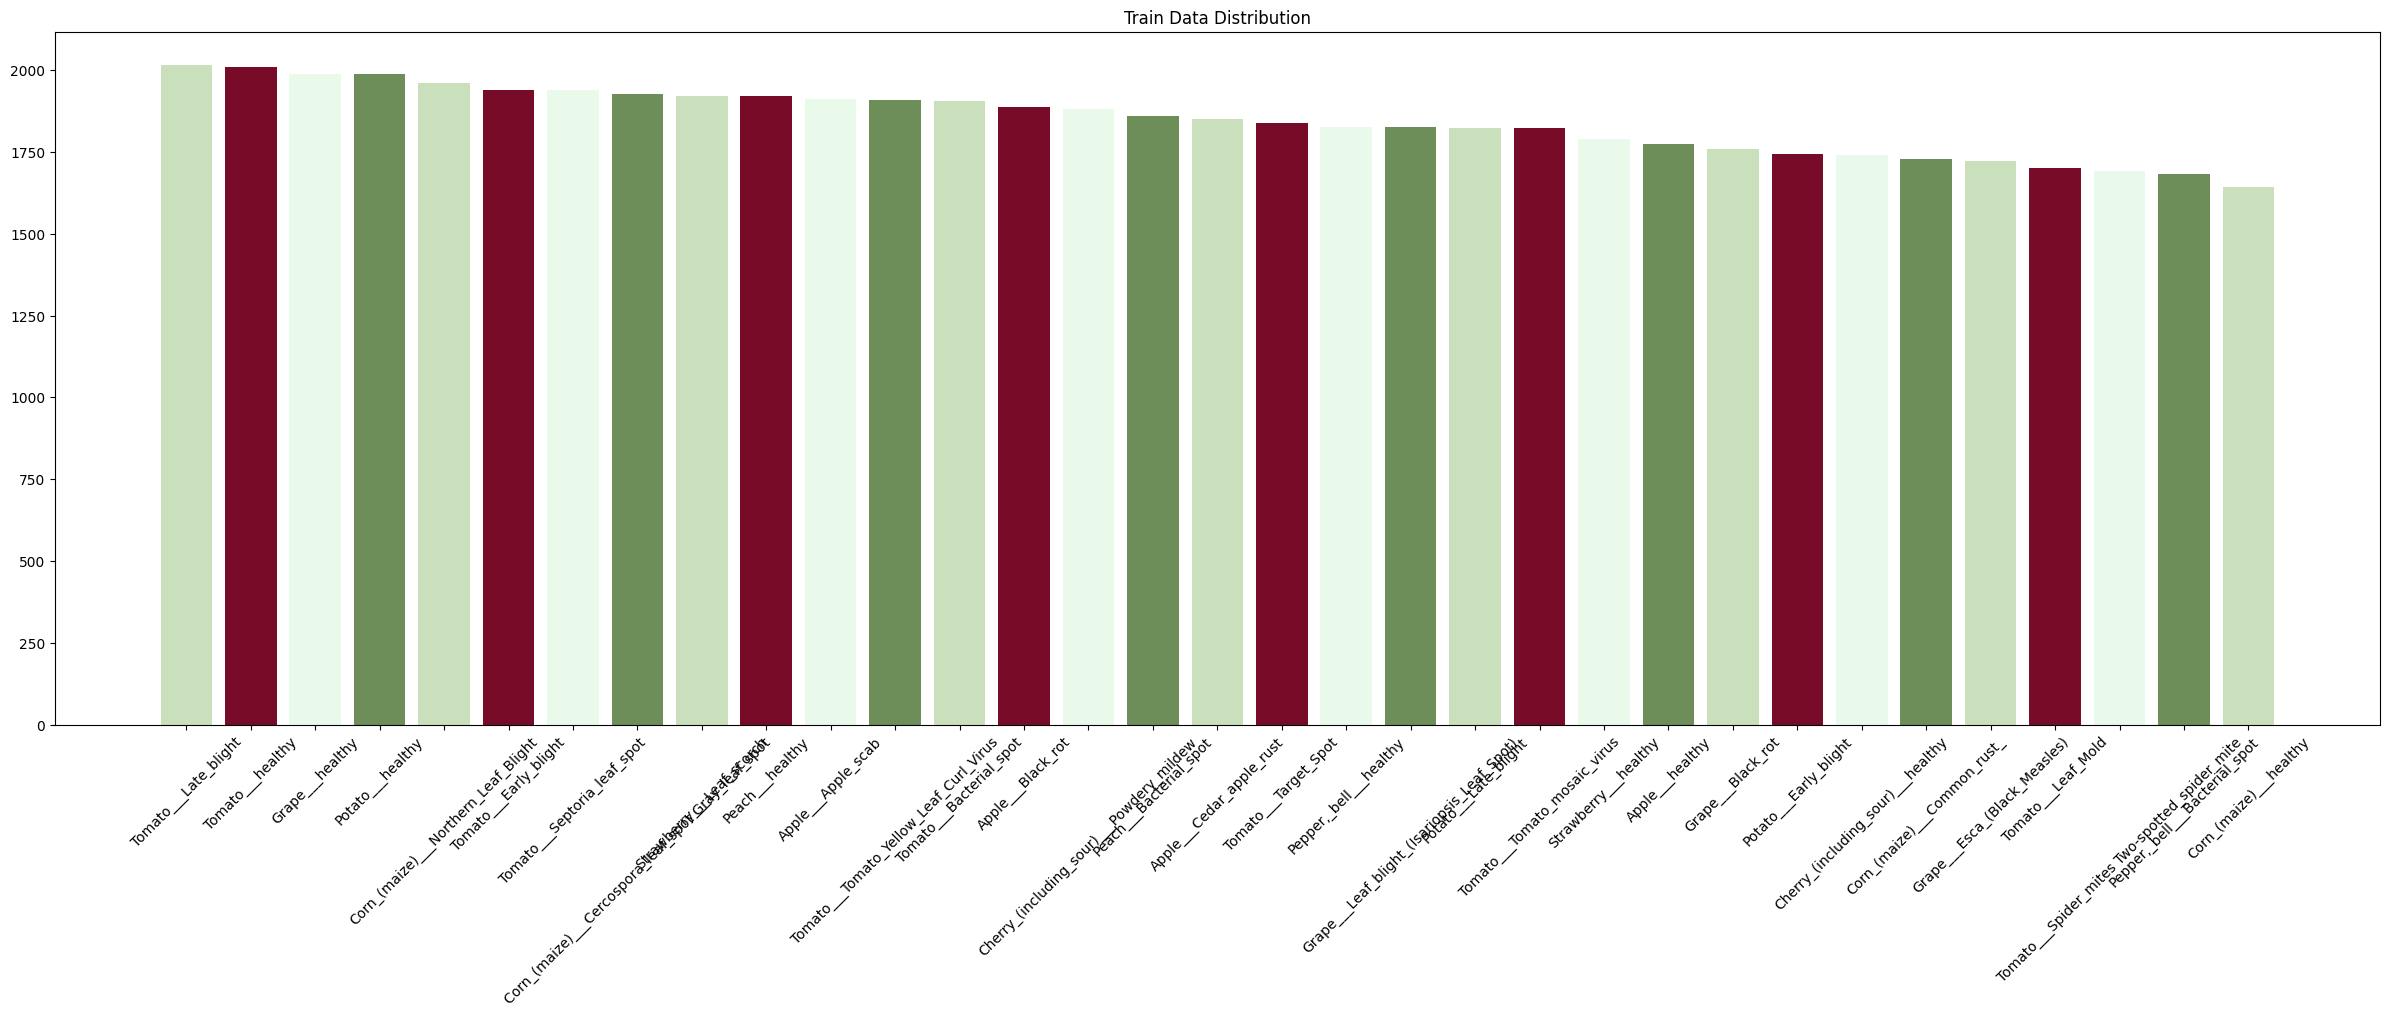

In [10]:
plt.figure(figsize=(30,9))
plt.bar(df_train['label'].unique(), df_train['label'].value_counts(), color=color)
plt.title('Train Data Distribution')
plt.xticks(rotation=45)
plt.show()

In [11]:
print(np.unique(label_train))


['Apple___Apple_scab' 'Apple___Black_rot' 'Apple___Cedar_apple_rust'
 'Apple___healthy' 'Cherry_(including_sour)___Powdery_mildew'
 'Cherry_(including_sour)___healthy'
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'
 'Corn_(maize)___Common_rust_' 'Corn_(maize)___Northern_Leaf_Blight'
 'Corn_(maize)___healthy' 'Grape___Black_rot'
 'Grape___Esca_(Black_Measles)'
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)' 'Grape___healthy'
 'Peach___Bacterial_spot' 'Peach___healthy'
 'Pepper,_bell___Bacterial_spot' 'Pepper,_bell___healthy'
 'Potato___Early_blight' 'Potato___Late_blight' 'Potato___healthy'
 'Strawberry___Leaf_scorch' 'Strawberry___healthy'
 'Tomato___Bacterial_spot' 'Tomato___Early_blight' 'Tomato___Late_blight'
 'Tomato___Leaf_Mold' 'Tomato___Septoria_leaf_spot'
 'Tomato___Spider_mites Two-spotted_spider_mite' 'Tomato___Target_Spot'
 'Tomato___Tomato_Yellow_Leaf_Curl_Virus' 'Tomato___Tomato_mosaic_virus'
 'Tomato___healthy']


In [12]:
data_gen  = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True)

# only normalization
test_gen = ImageDataGenerator(rescale=1./255)


imge_size = (224,224)
batch_size = 32

In [13]:
train_gen = data_gen.flow_from_dataframe(
    df_train,
    x_col='filename',
    shuffle=True,
    y_col='label',
    target_size=(imge_size[0],imge_size[1]),
    class_mode='categorical',
    batch_size=batch_size)

valid_gen = test_gen.flow_from_dataframe(
    df_valid,
    shuffle=False ,
    x_col='filename',
    y_col='label',
    target_size=(imge_size[0],imge_size[1]),
    class_mode='categorical')

Found 60930 validated image filenames belonging to 33 classes.
Found 15231 validated image filenames belonging to 33 classes.


In [14]:
class_dict = train_gen.class_indices
print(class_dict)

{'Apple___Apple_scab': 0, 'Apple___Black_rot': 1, 'Apple___Cedar_apple_rust': 2, 'Apple___healthy': 3, 'Cherry_(including_sour)___Powdery_mildew': 4, 'Cherry_(including_sour)___healthy': 5, 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 6, 'Corn_(maize)___Common_rust_': 7, 'Corn_(maize)___Northern_Leaf_Blight': 8, 'Corn_(maize)___healthy': 9, 'Grape___Black_rot': 10, 'Grape___Esca_(Black_Measles)': 11, 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': 12, 'Grape___healthy': 13, 'Peach___Bacterial_spot': 14, 'Peach___healthy': 15, 'Pepper,_bell___Bacterial_spot': 16, 'Pepper,_bell___healthy': 17, 'Potato___Early_blight': 18, 'Potato___Late_blight': 19, 'Potato___healthy': 20, 'Strawberry___Leaf_scorch': 21, 'Strawberry___healthy': 22, 'Tomato___Bacterial_spot': 23, 'Tomato___Early_blight': 24, 'Tomato___Late_blight': 25, 'Tomato___Leaf_Mold': 26, 'Tomato___Septoria_leaf_spot': 27, 'Tomato___Spider_mites Two-spotted_spider_mite': 28, 'Tomato___Target_Spot': 29, 'Tomato___Tomato_Yellow

In [15]:
Model = Sequential([
    Conv2D(64, kernel_size= (3,3),padding='same', activation='relu', input_shape=(imge_size[0],imge_size[1],3)),
    Conv2D(64, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(128, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(128, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    
    Conv2D(128, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(128, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(256, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(256, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(512, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(512, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(512, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(512, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(256, activation='relu'),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(33, activation='softmax') ])

In [16]:
Model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 128)       │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 56, 56, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 56, 56, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 28, 28, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 14, 14, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 14, 14, 512)         │           2,048 │
│ (BatchNormalization)                 │                             │              

 Total params: 10,905,057 (41.60 MB)

 Trainable params: 10,901,857 (41.59 MB)

 Non-trainable params: 3,200 (12.50 KB)

In [17]:
Model.compile(Adamax(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])


In [18]:
history = Model.fit(
    train_gen,
    epochs=40,
    validation_data=valid_gen,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
    verbose=1
    
    )

Epoch 1/40
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 1196s 609ms/step - accuracy: 0.3228 - loss: 2.4964 - val_accuracy: 0.7172 - val_loss: 0.9397
Epoch 2/40
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 840s 440ms/step - accuracy: 0.7755 - loss: 0.7798 - val_accuracy: 0.8936 - val_loss: 0.3516
Epoch 3/40
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 823s 431ms/step - accuracy: 0.8833 - loss: 0.4003 - val_accuracy: 0.7561 - val_loss: 0.9331
Epoch 4/40
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 842s 441ms/step - accuracy: 0.9231 - loss: 0.2684 - val_accuracy: 0.8537 - val_loss: 0.5071
Epoch 5/40
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 842s 441ms/step - accuracy: 0.9465 - loss: 0.1901 - val_accuracy: 0.9087 - val_loss: 0.3279
Epoch 6/40
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 833s 436ms/step - accuracy: 0.9576 - loss: 0.1465 - val_accuracy: 0.7415 - val_loss: 1.2076
Epoch 7/40
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 852s 446ms/step - accuracy: 0.9648 - loss: 0.1186 - val_accuracy: 0.6880 - val_loss: 2.0916
Epoch 8/40
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 835s 437ms/step - a

In [19]:
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=(imge_size[0], imge_size[1]),
    shuffle=False,
    labels=None  
)

Found 33 files.


In [20]:
print(Model.evaluate(train_gen))
print(Model.evaluate(valid_gen))

1905/1905 ━━━━━━━━━━━━━━━━━━━━ 672s 352ms/step - accuracy: 0.9943 - loss: 0.0179
[0.017969194799661636, 0.9944034218788147]
476/476 ━━━━━━━━━━━━━━━━━━━━ 169s 354ms/step - accuracy: 0.9876 - loss: 0.0503
[0.03439360111951828, 0.9904142618179321]


In [21]:
Model.save('Modelplanit_CNN.h5')


In [22]:
preds = Model.predict(valid_gen)
y_pred = np.argmax(preds, axis=1)

476/476 ━━━━━━━━━━━━━━━━━━━━ 157s 328ms/step


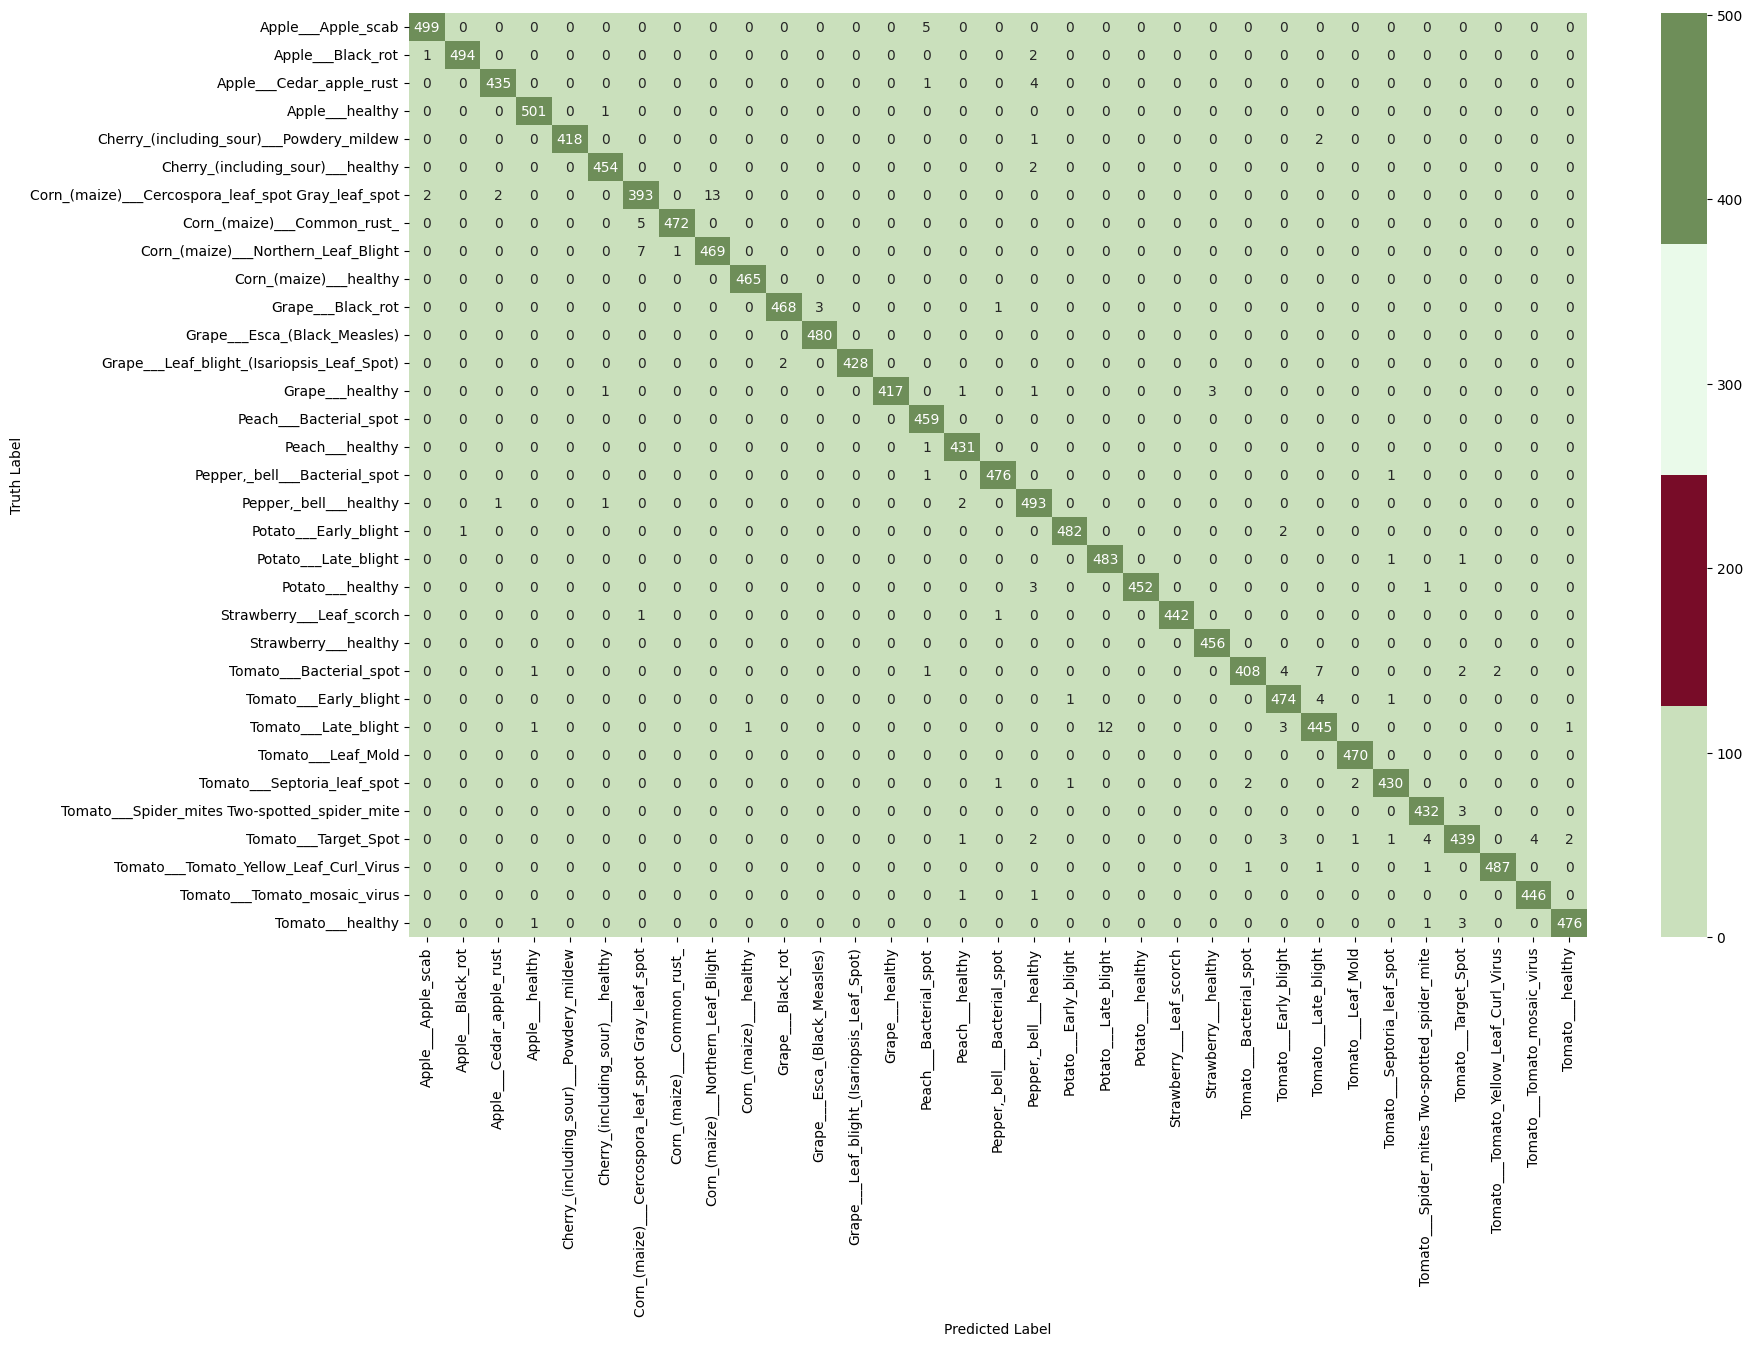

In [23]:
cm = confusion_matrix(valid_gen.classes, y_pred)
labels = list(class_dict.keys())
plt.figure(figsize=(19,12))
sns.heatmap(cm, annot=True, fmt='d', cmap=color, xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Label')
plt.ylabel('Truth Label')
plt.show()

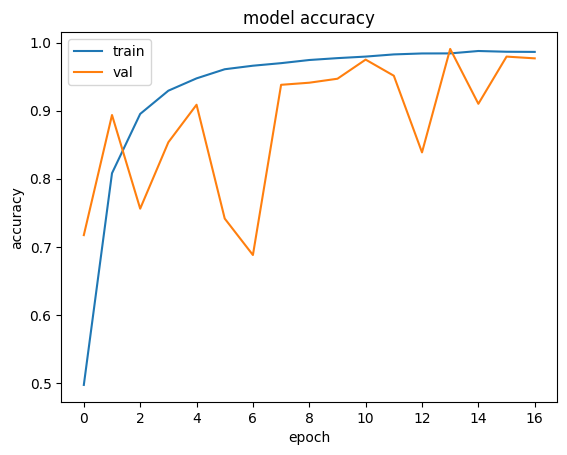

In [24]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')

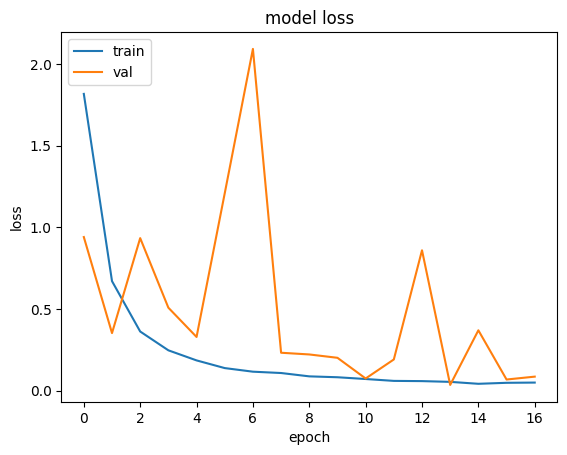

In [25]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')

In [26]:
def predict(img_path):

    
    label = list(class_dict.keys())
    plt.figure(figsize=(12, 19))
    img = Image.open(img_path)
    resized_img = img.resize((224, 224))
    img = np.asarray(resized_img)
    img = np.expand_dims(img, axis=0)
    img = img / 255
    predictions = Model.predict(img)
    probs = list(predictions[0])
    labels = label
    plt.subplot(2, 1, 1)
    plt.imshow(resized_img)
    plt.subplot(2, 1, 2)
    bars = plt.barh(labels, probs)
    plt.xlabel('Probability', fontsize=15)
    ax = plt.gca()
    ax.bar_label(bars, fmt = '%.2f')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


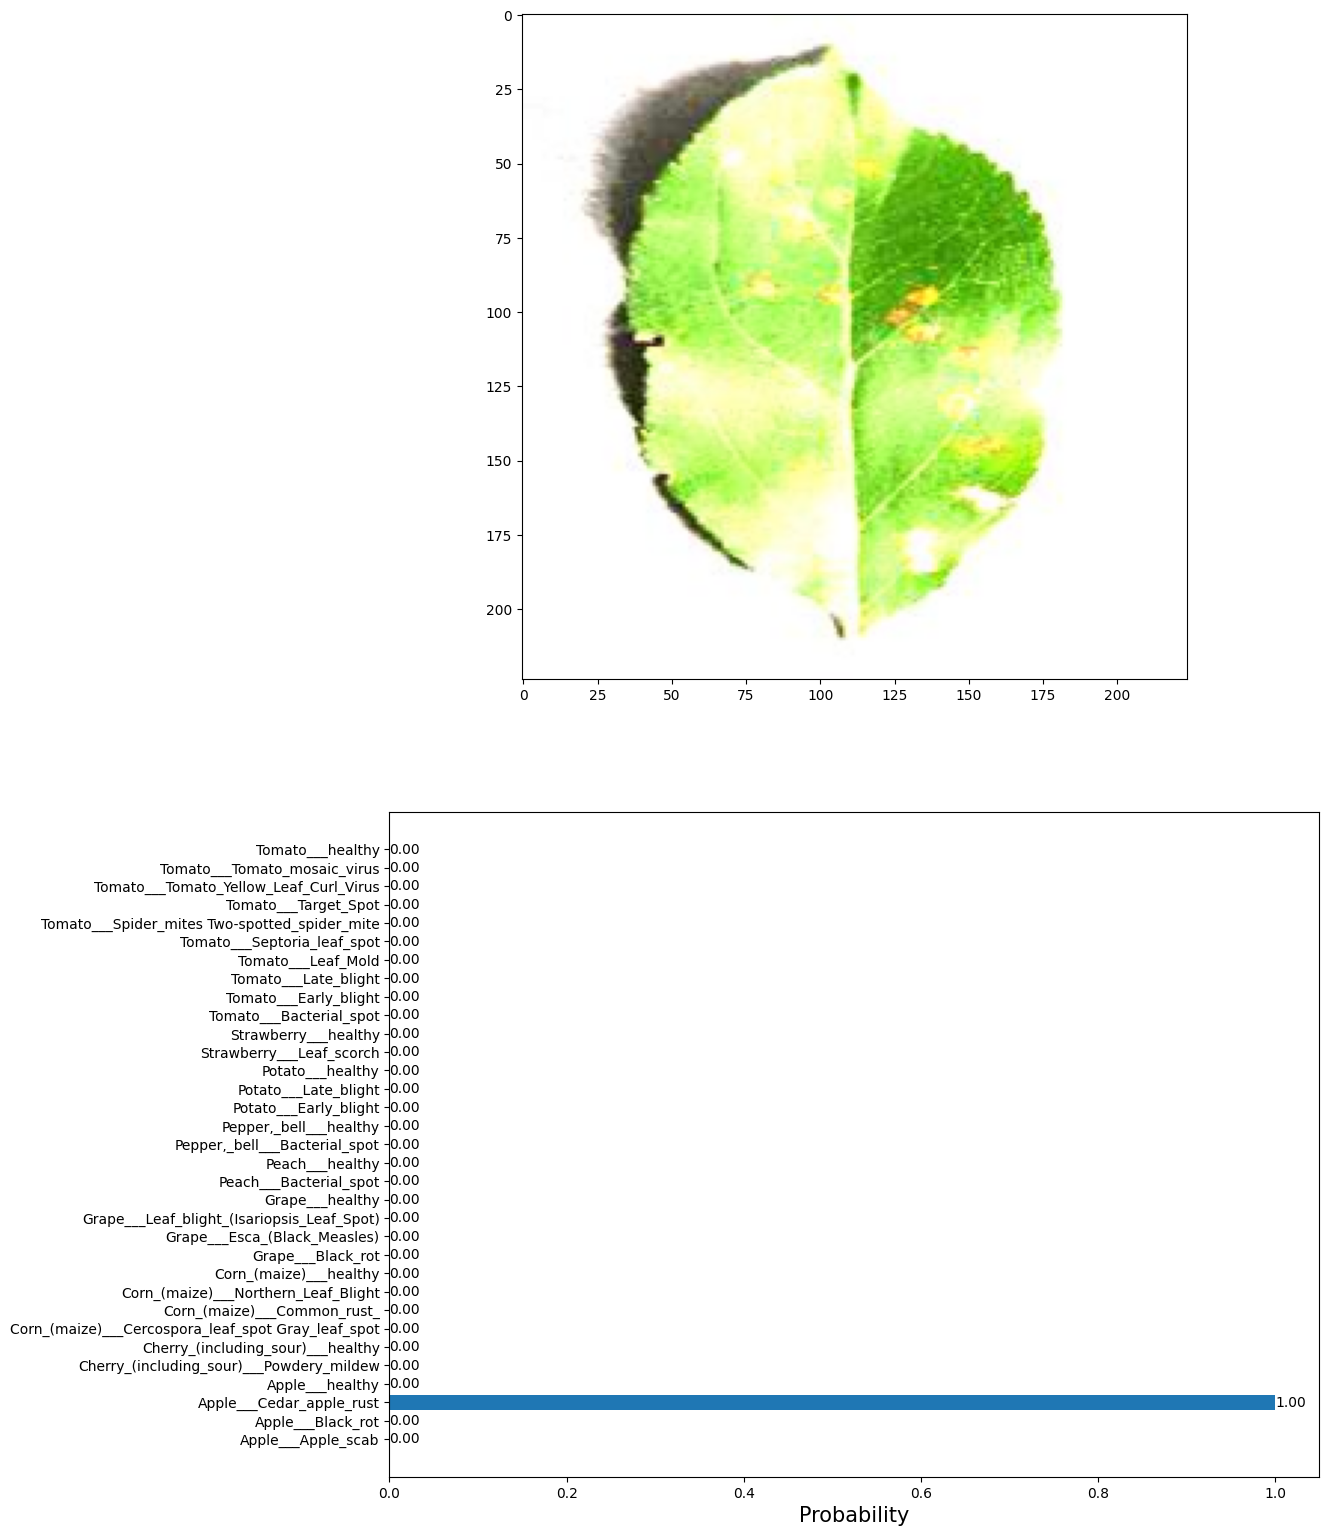

In [27]:
predict('/kaggle/input/plantvillage-dataset/test/test/AppleCedarRust1.JPG')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


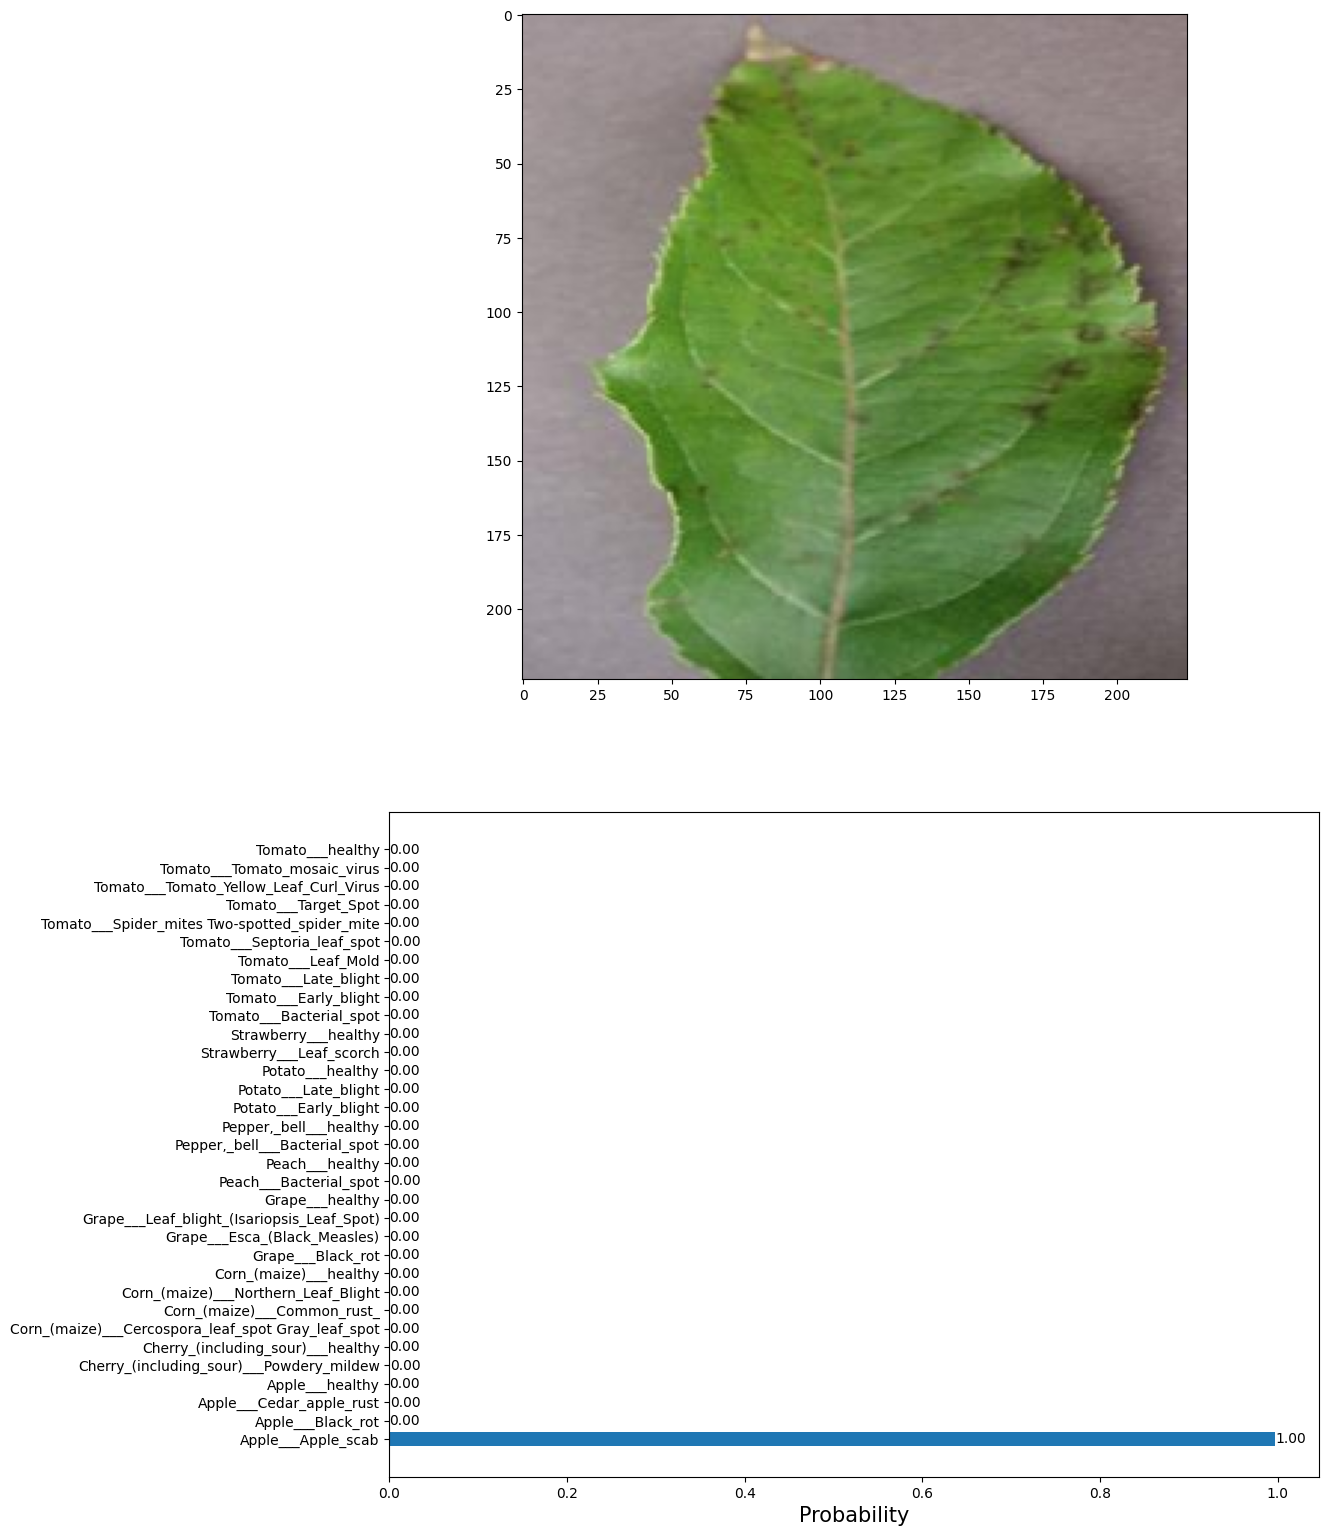

In [28]:
predict('/kaggle/input/plantvillage-dataset/test/test/AppleScab1.JPG')


In [29]:
base_model = tf.keras.applications.EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_shape=(imge_size[0],imge_size[1],3),
    pooling='max',
)

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [30]:
ModelPretrained = Sequential([
    base_model,
    
    Dense(256 , activation='relu'),
    Dropout(0.3),
    Dense(33, activation='softmax')
    
])
ModelPretrained.compile(optimizer=Adamax(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

In [31]:
history_Final = ModelPretrained.fit(
    train_gen, 
    epochs=5, 
    validation_data=valid_gen, 
    verbose=1, 
    
)

Epoch 1/5
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 1064s 501ms/step - accuracy: 0.7662 - loss: 1.0069 - val_accuracy: 0.9888 - val_loss: 0.0384
Epoch 2/5
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 878s 459ms/step - accuracy: 0.9765 - loss: 0.0780 - val_accuracy: 0.9911 - val_loss: 0.0285
Epoch 3/5
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 855s 447ms/step - accuracy: 0.9867 - loss: 0.0423 - val_accuracy: 0.9945 - val_loss: 0.0191
Epoch 4/5
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 849s 444ms/step - accuracy: 0.9909 - loss: 0.0296 - val_accuracy: 0.9955 - val_loss: 0.0144
Epoch 5/5
1905/1905 ━━━━━━━━━━━━━━━━━━━━ 892s 467ms/step - accuracy: 0.9919 - loss: 0.0295 - val_accuracy: 0.9955 - val_loss: 0.0135


In [32]:
print(ModelPretrained.evaluate(train_gen))
print(ModelPretrained.evaluate(valid_gen))

1905/1905 ━━━━━━━━━━━━━━━━━━━━ 682s 358ms/step - accuracy: 0.9980 - loss: 0.0078
[0.006336441729217768, 0.9982603192329407]
476/476 ━━━━━━━━━━━━━━━━━━━━ 170s 357ms/step - accuracy: 0.9963 - loss: 0.0167
[0.012284352444112301, 0.9967828989028931]


In [33]:
ModelPretrained.save('Plant_Village_Detection_Model.h5')


In [34]:
preds = ModelPretrained.predict(valid_gen)
y_pred_ModelPretrained = np.argmax(preds, axis=1)

476/476 ━━━━━━━━━━━━━━━━━━━━ 171s 342ms/step


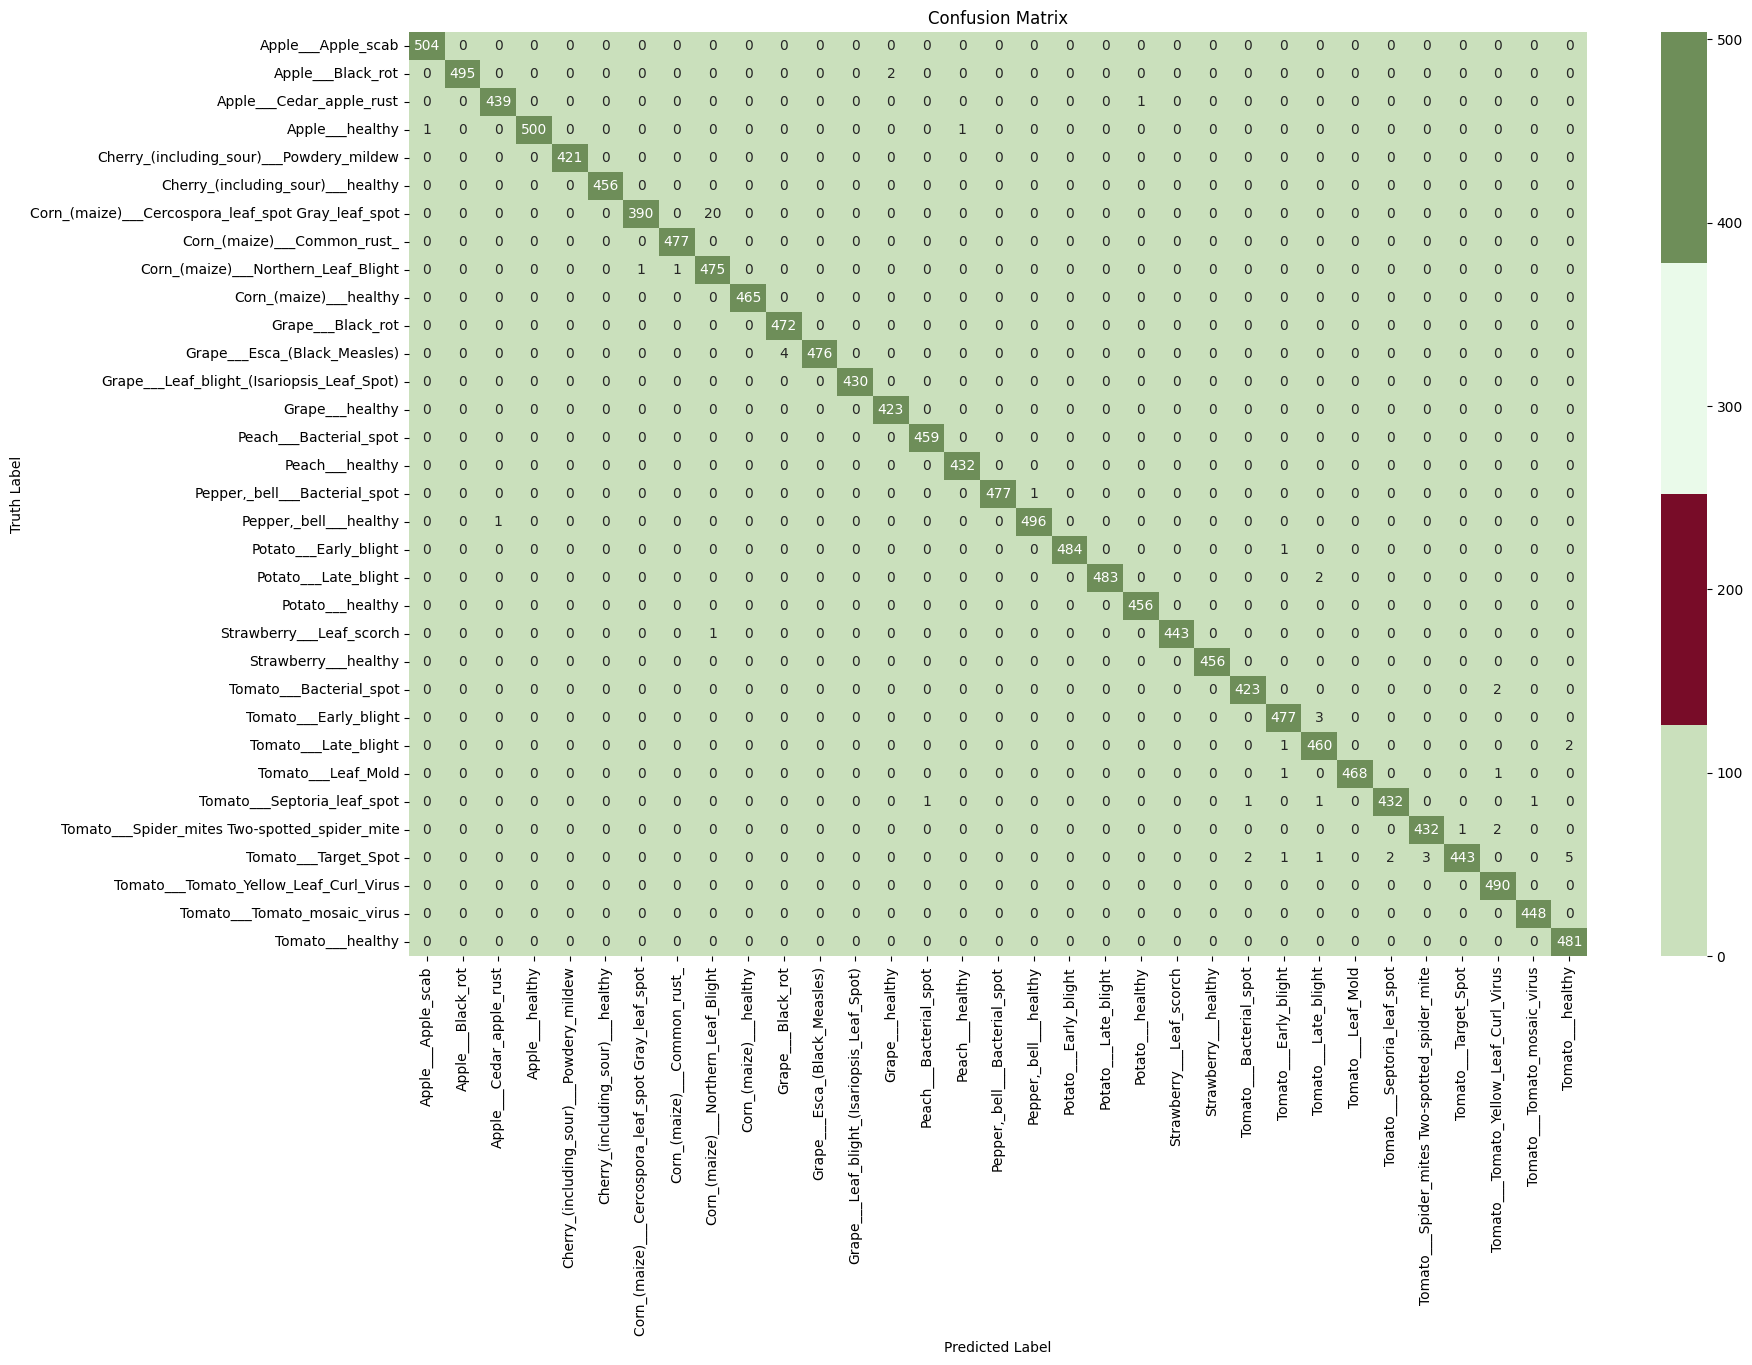

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00       504
                                 Apple___Black_rot       1.00      1.00      1.00       497
                          Apple___Cedar_apple_rust       1.00      1.00      1.00       440
                                   Apple___healthy       1.00      1.00      1.00       502
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       421
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       1.00      0.95      0.97       410
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       477
               Corn_(maize)___Northern_Leaf_Blight       0.96      1.00      0.98       477
                            Corn_(maize)___healthy      

In [35]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(valid_gen.classes, y_pred_ModelPretrained)
labels = list(class_dict.keys())

plt.figure(figsize=(19,12))
sns.heatmap(cm, annot=True, fmt='d', cmap=color, xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Label')
plt.ylabel('Truth Label')
plt.title('Confusion Matrix')
plt.show()

print("Classification Report:")
print(classification_report(valid_gen.classes, y_pred_ModelPretrained, target_names=labels))


In [36]:
def predict(img_path):

    
    label = list(class_dict.keys())
    plt.figure(figsize=(12, 19))
    img = Image.open(img_path)
    resized_img = img.resize((224, 224))
    img = np.asarray(resized_img)
    img = np.expand_dims(img, axis=0)
    img = img / 255
    predictions = ModelPretrained.predict(img)
    probs = list(predictions[0])
    labels = label
    plt.subplot(2, 1, 1)
    plt.imshow(resized_img)
    plt.subplot(2, 1, 2)
    bars = plt.barh(labels, probs)
    plt.xlabel('Probability', fontsize=15)
    ax = plt.gca()
    ax.bar_label(bars, fmt = '%.2f')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step


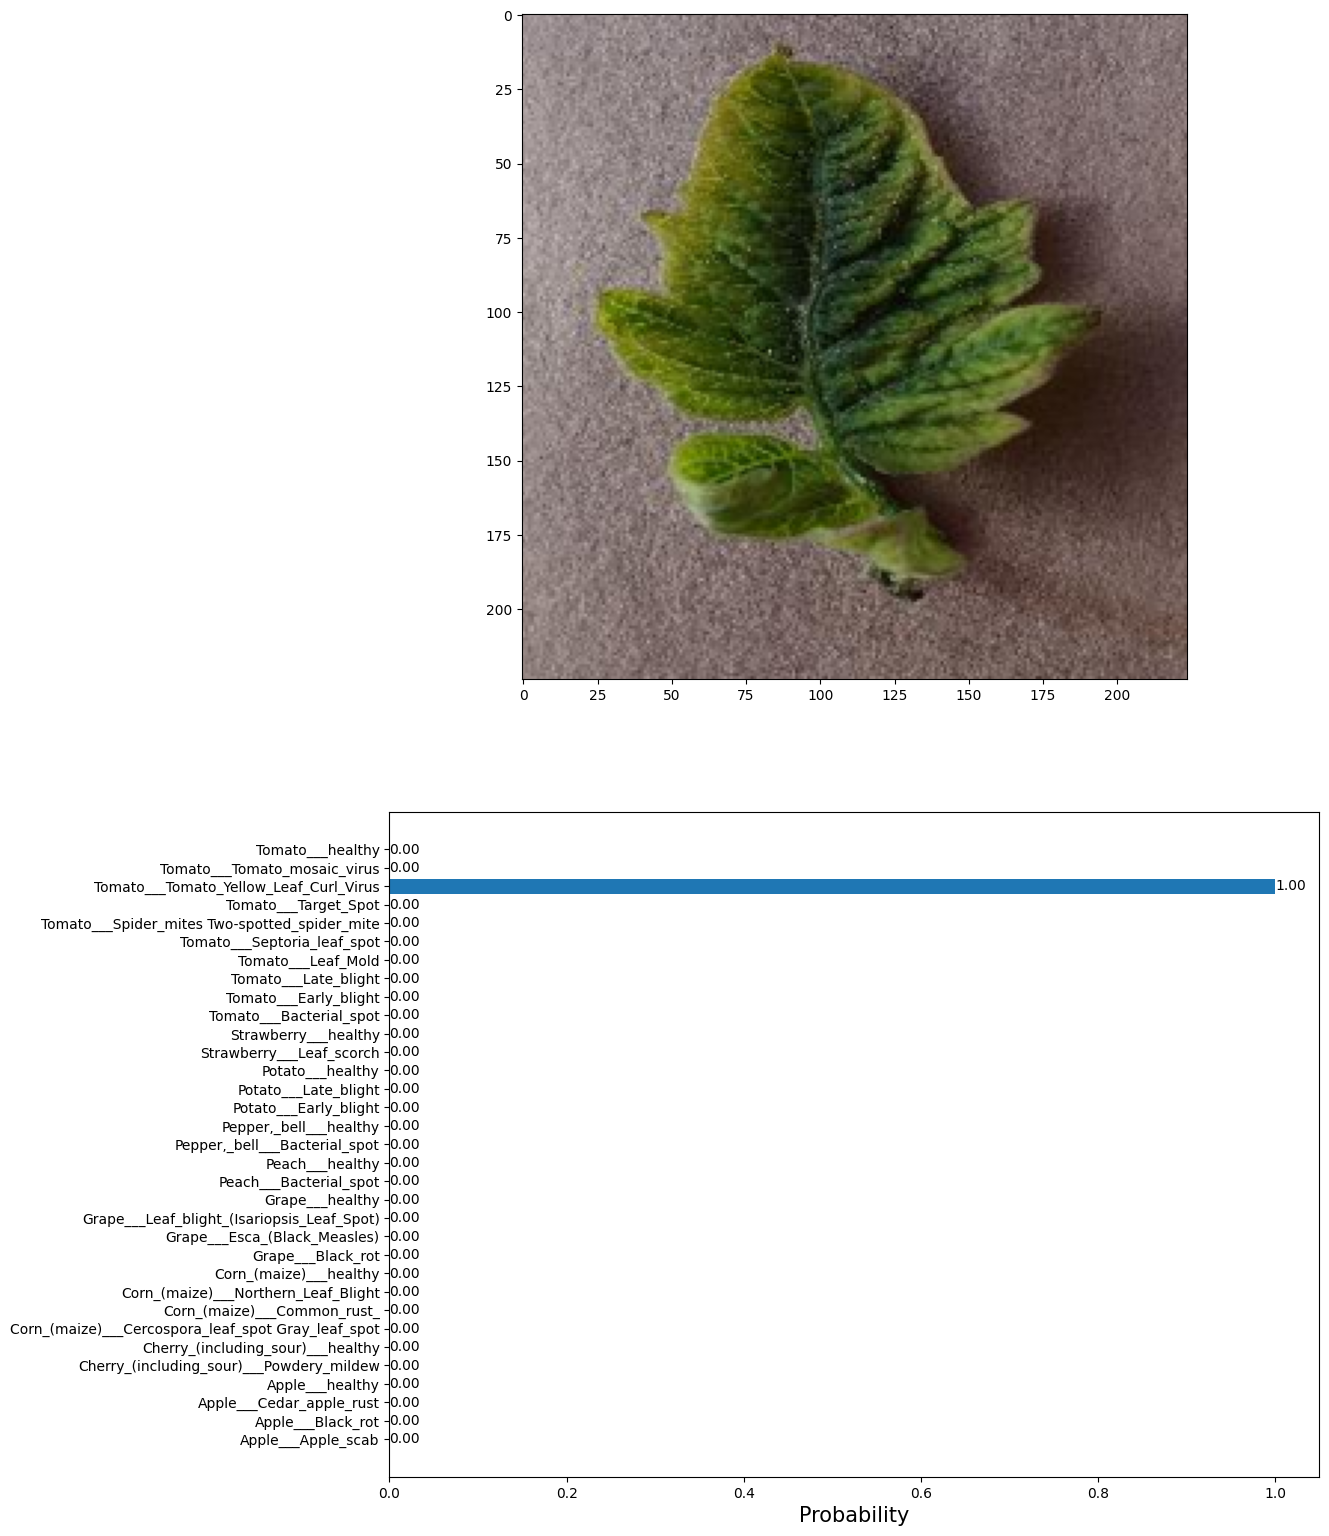

In [37]:
predict('/kaggle/input/plantvillage-dataset/test/test/TomatoYellowCurlVirus1.JPG')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


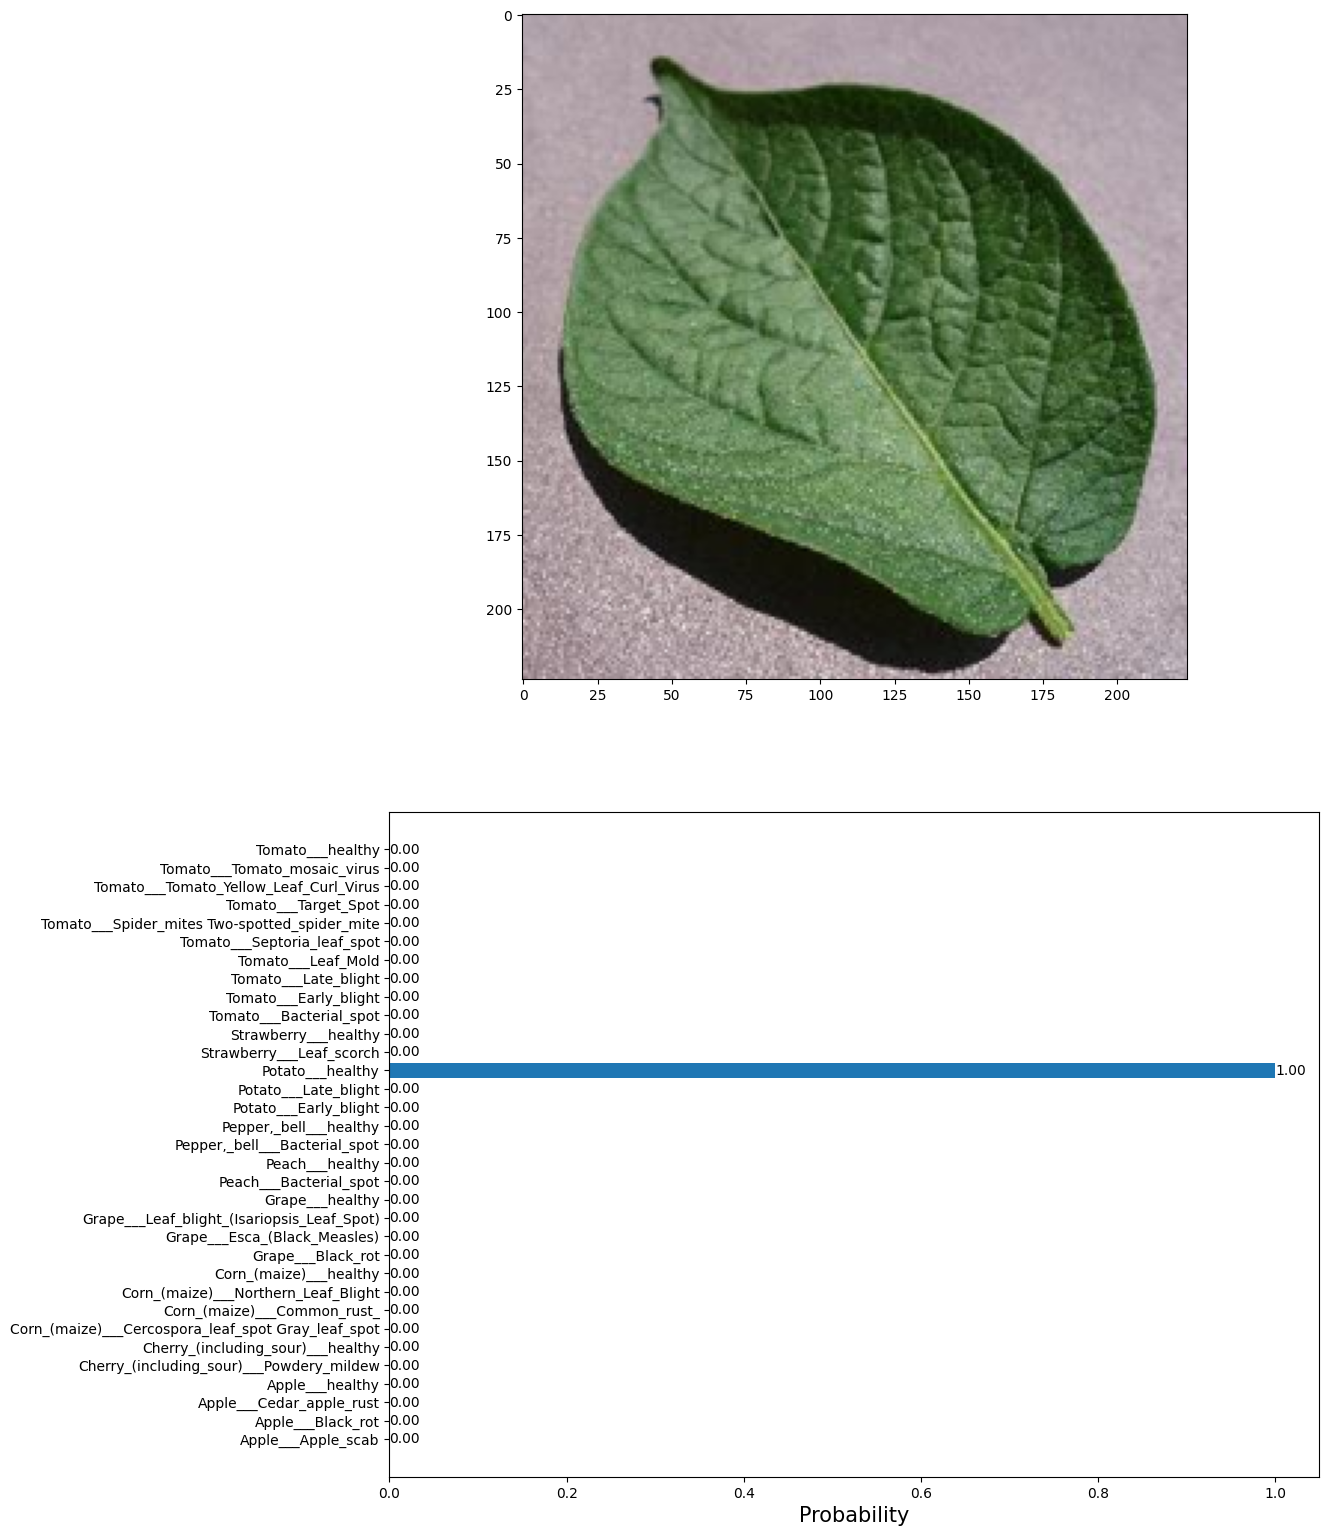

In [38]:
predict('/kaggle/input/plantvillage-dataset/test/test/PotatoHealthy1.JPG')


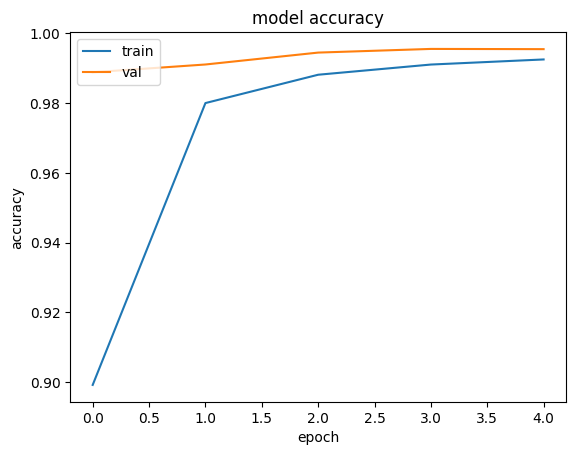

In [39]:
plt.plot(history_Final.history['accuracy'])
plt.plot(history_Final.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')